# Módulo 6: simulador de temporada y playoffs

**Preguntas:**
- **F.** ¿Qué tan bien calibrado está el rango de victorias que da un simulador basado en Elo?
- **G.** ¿Qué probabilidad de ser campeón le da al favorito, y con qué frecuencia el campeón sale de los favoritos?
- Y la pregunta práctica: ¿qué dice el simulador de la temporada 2026-27 en curso, y cuánto creerle?

**Diseño (decidido antes de ver los datos):**
- Cada simulación juega los partidos que faltan con la probabilidad de Elo (K=24, ventaja de local 40, los parámetros del Módulo 1), ordena cada conferencia, juega el play-in y un cuadro fijo de playoffs con series a 7 (2-2-1-1-1).
- **Backtest antes de usarlo:** cinco temporadas terminadas (2021-22 a 2025-26), con cortes al 10, 30, 50 y 70 % del calendario, usando solo lo conocido en cada corte y el calendario real restante.
- Métricas con baselines: cobertura de los rangos de victorias, error de victorias contra la extrapolación simple, Brier de "clasifica a playoffs" contra una constante y contra "está en el top 8 hoy", y log score del campeón contra el uniforme (ln 30 = 3.40).

**Mis hipótesis previas:** ninguna ("sin intuición, corre"). Referencias: un rango del 80 % debería contener al ~80 % de los equipos; el uniforme da 1/30 de probabilidad a cada candidato.

Para reproducir: `python -m uv run python scripts/season_backtest.py` (unos minutos, guarda `data/processed/season_backtest_grid.parquet`), luego `python -m uv run jupyter lab`.

In [1]:
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sportslab.config import PROCESSED_DIR
from sportslab.data import NbaClient
from sportslab.data.games import load_games, season_labels
from sportslab.data.schedule import load_conferences, load_schedule
from sportslab.models.elo import EloParams
from sportslab.models.metrics import calibration_table
from sportslab.models.season_backtest import summarize_backtest
from sportslab.models.season_sim import (
    VALIDATED_RATING_SD,
    SimConfig,
    series_win_prob,
    simulate_season,
)
from sportslab.models.season_state import build_season_state

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200

TUNED_ELO = EloParams(k=24, home_advantage=40, carryover=0.7)
N_SIMS = 4000  # simulations per backtest run, as in scripts/season_backtest.py
grid = pd.read_parquet(PROCESSED_DIR / "season_backtest_grid.parquet")
summary = summarize_backtest(grid, N_SIMS)
print(
    f"{len(grid):,} filas: {grid['season'].nunique()} temporadas x {grid['cutoff'].nunique()} cortes x "
    f"{grid['rating_sd'].nunique()} valores de incertidumbre x 30 equipos"
)

3,600 filas: 5 temporadas x 4 cortes x 6 valores de incertidumbre x 30 equipos


## 0. Hallazgos de datos antes de empezar

1. **El calendario de 2026-27 está incompleto**: NBA.com lista 80 partidos por equipo (no 82), y 12 filas tienen un rival "por definir" (id 0). Los dos partidos que faltan por equipo se simulan contra un rival promedio en sede neutral, y la página lo avisa; no se esconde.
2. **Los resultados de playoffs se extraen bien**: de los partidos de playoffs sale quién clasificó (16), los finalistas y el campeón; coinciden con los campeones conocidos (Warriors 2021-22, Nuggets 2022-23, Celtics 2023-24, Thunder 2024-25).
3. **El Elo solo ve temporada regular.** Un campeón puede tener un Elo mediocre si su temporada regular lo fue (los playoffs no entran en el rating): una limitación, no un error.

## 1. Por qué una serie a 7 amplifica al favorito

Una ventaja pequeña por partido se convierte en una ventaja grande por serie (el mejor de 7 elimina mucho azar). Con ventaja de local 2-2-1-1-1 y el mismo p en casa y de visita:

 p por partido  p de ganar la serie
         0.500                0.500
         0.550                0.608
         0.600                0.710
         0.650                0.800
         0.700                0.874
         0.750                0.929
         0.800                0.967


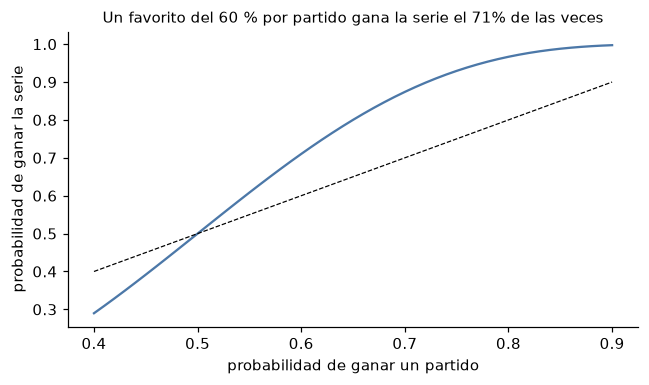

In [2]:
ps = np.array([0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80])
table = pd.DataFrame({"p por partido": ps, "p de ganar la serie": series_win_prob(ps, ps)})
print(table.to_string(index=False))
fig, ax = plt.subplots(figsize=(6, 3.6))
x = np.linspace(0.4, 0.9, 51)
ax.plot(x, series_win_prob(x, x), color="#4C78A8")
ax.plot(x, x, color="k", lw=0.8, ls="--")
ax.set_xlabel("probabilidad de ganar un partido")
ax.set_ylabel("probabilidad de ganar la serie")
ax.set_title(
    f"Un favorito del 60 % por partido gana la serie el {series_win_prob(0.6, 0.6):.0%} de las veces",
    fontsize=10,
)
plt.tight_layout()
plt.show()

## 2. Hipótesis F: ¿está calibrado el rango de victorias?

Primera versión: ratings congelados en el corte (el Elo se trata como la verdad). Después, la corrección que mostró el backtest.

Cobertura de los rangos con ratings congelados (rating_sd = 0), por corte:
        coverage_50%  coverage_80%  coverage_90%
cutoff                                          
0.100          0.287         0.467         0.533
0.300          0.360         0.553         0.647
0.500          0.327         0.600         0.700
0.700          0.500         0.727         0.833

           coverage_50%  coverage_80%  coverage_90%
rating_sd                                          
0                 0.368         0.587         0.678
25                0.393         0.612         0.733
50                0.457         0.708         0.838
75                0.545         0.828         0.912
100               0.600         0.890         0.955
150               0.723         0.963         0.988


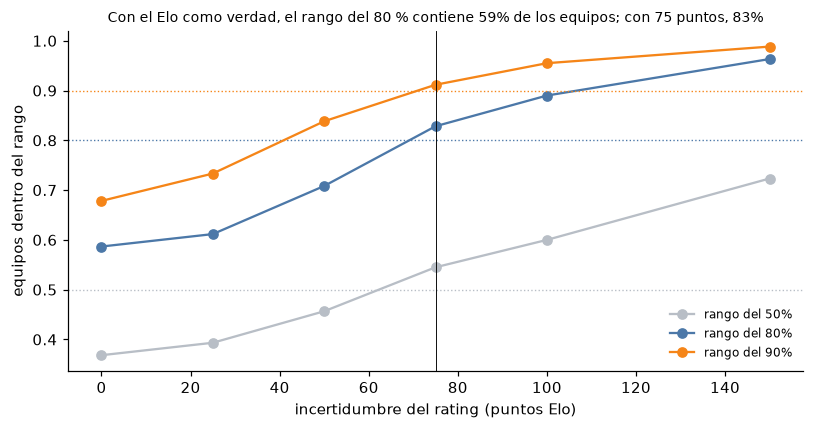

In [3]:
frozen = summary[summary["rating_sd"] == 0]
print("Cobertura de los rangos con ratings congelados (rating_sd = 0), por corte:")
print(frozen.groupby("cutoff")[["coverage_50%", "coverage_80%", "coverage_90%"]].mean().to_string())
print()
by_sd = summary.groupby("rating_sd")[["coverage_50%", "coverage_80%", "coverage_90%"]].mean()
print(by_sd.to_string())

fig, ax = plt.subplots(figsize=(7.5, 4))
for col, nominal, color in (
    ("coverage_50%", 0.5, "#B8BEC6"),
    ("coverage_80%", 0.8, "#4C78A8"),
    ("coverage_90%", 0.9, "#F58518"),
):
    ax.plot(by_sd.index, by_sd[col], marker="o", color=color, label=f"rango del {nominal:.0%}")
    ax.axhline(nominal, color=color, ls=":", lw=0.9)
ax.axvline(VALIDATED_RATING_SD, color="k", lw=0.6)
ax.set_xlabel("incertidumbre del rating (puntos Elo)")
ax.set_ylabel("equipos dentro del rango")
ax.set_title(
    f"Con el Elo como verdad, el rango del 80 % contiene {by_sd.loc[0, 'coverage_80%']:.0%} de los equipos; "
    f"con {int(VALIDATED_RATING_SD)} puntos, {by_sd.loc[int(VALIDATED_RATING_SD), 'coverage_80%']:.0%}",
    fontsize=9,
)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de F.** Con el Elo como verdad, el simulador está **demasiado seguro**: el rango del 80 % contiene solo ~59 % de los equipos (el del 50 %, ~37 %). Es el error clásico: un rating es una *estimación* de la fuerza real del equipo, y tratarla como verdad ignora esa incertidumbre. Dar a cada equipo, en cada corrida, una fuerza real sacada de una campana centrada en su Elo (desviación de ~75 puntos, equivalente a unos ±2 puntos por partido) deja la cobertura casi nominal.

**Cuidado con lo que acabo de hacer:** elegí el 75 mirando el backtest, así que hace falta medirlo fuera de muestra: eso es lo siguiente.

## 3. ¿Se sostiene fuera de muestra? Dejar una temporada fuera

In [4]:
nominal = {"coverage_50%": 0.5, "coverage_80%": 0.8, "coverage_90%": 0.9}
summary["gap"] = sum((summary[c] - n).abs() for c, n in nominal.items()) / 3
rows = []
for held in sorted(summary["season"].unique()):
    train = summary[summary["season"] != held].groupby("rating_sd")["gap"].mean()
    best = float(train.idxmin())
    test = summary[(summary["season"] == held) & (summary["rating_sd"] == best)]
    zero = summary[(summary["season"] == held) & (summary["rating_sd"] == 0)]
    rows.append(
        {
            "temporada fuera": held,
            "sd elegido": best,
            "cobertura 80% (elegido)": test["coverage_80%"].mean(),
            "cobertura 80% (congelado)": zero["coverage_80%"].mean(),
        }
    )
loso = pd.DataFrame(rows)
print(loso.to_string(index=False))
print(
    f"Promedio: elegido {loso['cobertura 80% (elegido)'].mean():.2f} vs congelado {loso['cobertura 80% (congelado)'].mean():.2f}"
)

temporada fuera  sd elegido  cobertura 80% (elegido)  cobertura 80% (congelado)
        2021-22      75.000                    0.825                      0.575
        2022-23      75.000                    0.842                      0.650
        2023-24      75.000                    0.875                      0.608
        2024-25      75.000                    0.817                      0.567
        2025-26      75.000                    0.783                      0.533
Promedio: elegido 0.83 vs congelado 0.59


Elegido con las otras cuatro temporadas, el 75 gana todas las veces y la cobertura del 80 % fuera de muestra queda entre ~78 y ~88 % (promedio ~83 %), contra ~59 % con ratings congelados. Es una mejora genuina, aunque con cinco temporadas y un solo parámetro no hay mucho margen para sobreajustar, y las temporadas no son independientes (comparten equipos y jugadores).

## 4. Probabilidades de playoffs y de título (con rating_sd = 75)

 bin   n  mean_pred  observed  ci_low  ci_high
   0 126      0.023     0.024   0.008    0.068
   1  35      0.152     0.286   0.163    0.451
   2  29      0.238     0.138   0.055    0.306
   3  29      0.354     0.241   0.122    0.421
   4  43      0.454     0.535   0.389    0.675
   5  42      0.547     0.571   0.422    0.709
   6  59      0.653     0.644   0.517    0.754
   7  40      0.754     0.750   0.598    0.858
   8  67      0.853     0.821   0.713    0.894
   9 130      0.971     0.969   0.924    0.988

        brier_playoffs_sim  brier_playoffs_top8  brier_playoffs_const  logscore_title  top_title_prob  p_champion_actual
cutoff                                                                                                                  
0.100                0.189                0.267                 0.249           2.598           0.235              0.088
0.300                0.131                0.173                 0.249           2.250           0.336              0.13

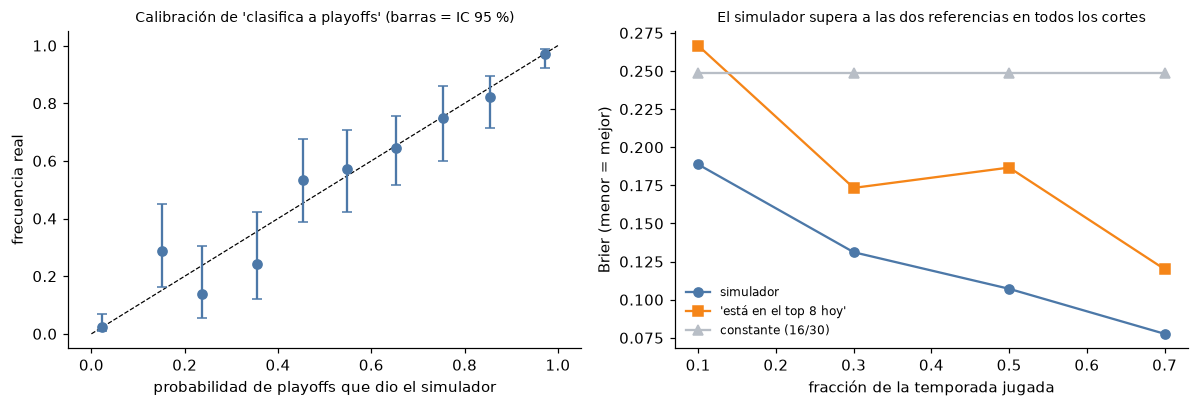

In [5]:
best = grid[grid["rating_sd"] == VALIDATED_RATING_SD]
cal = calibration_table(
    best["made_playoffs"].astype(float).to_numpy(), best["p_playoffs"].to_numpy(), n_bins=10
)
print(cal.round(3).to_string(index=False))

sm = summary[summary["rating_sd"] == VALIDATED_RATING_SD]
by_cut = sm.groupby("cutoff")[
    [
        "brier_playoffs_sim",
        "brier_playoffs_top8",
        "brier_playoffs_const",
        "logscore_title",
        "top_title_prob",
        "p_champion_actual",
    ]
].mean()
print()
print(by_cut.to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
ax.errorbar(
    cal["mean_pred"],
    cal["observed"],
    yerr=[cal["observed"] - cal["ci_low"], cal["ci_high"] - cal["observed"]],
    fmt="o",
    color="#4C78A8",
    capsize=3,
)
ax.set_xlabel("probabilidad de playoffs que dio el simulador")
ax.set_ylabel("frecuencia real")
ax.set_title("Calibración de 'clasifica a playoffs' (barras = IC 95 %)", fontsize=9)
ax = axes[1]
ax.plot(by_cut.index, by_cut["brier_playoffs_sim"], marker="o", color="#4C78A8", label="simulador")
ax.plot(
    by_cut.index,
    by_cut["brier_playoffs_top8"],
    marker="s",
    color="#F58518",
    label="'está en el top 8 hoy'",
)
ax.plot(
    by_cut.index,
    by_cut["brier_playoffs_const"],
    marker="^",
    color="#B8BEC6",
    label="constante (16/30)",
)
ax.set_xlabel("fracción de la temporada jugada")
ax.set_ylabel("Brier (menor = mejor)")
ax.set_title("El simulador supera a las dos referencias en todos los cortes", fontsize=9)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
fav = []
for (season, cutoff), g in best.groupby(["season", "cutoff"]):
    top = g.loc[g["p_champion"].idxmax()]
    fav.append(
        {
            "season": season,
            "cutoff": cutoff,
            "p_favorito": top["p_champion"],
            "campeon": bool(top["is_champion"]),
            "p_del_campeon": g.loc[g["is_champion"], "p_champion"].iloc[0],
            "rank_del_campeon": int(
                (g["p_champion"] > g.loc[g["is_champion"], "p_champion"].iloc[0]).sum()
            )
            + 1,
        }
    )
fav = pd.DataFrame(fav)
print(fav.round(3).to_string(index=False))
print(
    f"\nProbabilidad media del favorito: {fav['p_favorito'].mean():.2f}; el favorito fue campeón {fav['campeon'].mean():.0%} "
    f"de las {len(fav)} veces ({int(fav['campeon'].sum())})"
)
print(
    f"El campeón estaba entre los 3 primeros en {(fav['rank_del_campeon'] <= 3).mean():.0%} de los casos"
)
print(
    f"Log score medio del campeón: {sm['logscore_title'].mean():.2f} (uniforme: {np.log(30):.2f})"
)

 season  cutoff  p_favorito  campeon  p_del_campeon  rank_del_campeon
2021-22   0.100       0.172    False          0.058                 6
2021-22   0.300       0.334    False          0.139                 2
2021-22   0.500       0.246    False          0.135                 3
2021-22   0.700       0.408    False          0.067                 4
2022-23   0.100       0.222    False          0.034                 9
2022-23   0.300       0.294    False          0.032                 7
2022-23   0.500       0.170    False          0.128                 4
2022-23   0.700       0.176     True          0.176                 1
2023-24   0.100       0.196    False          0.155                 2
2023-24   0.300       0.248     True          0.248                 1
2023-24   0.500       0.244     True          0.244                 1
2023-24   0.700       0.364     True          0.364                 1
2024-25   0.100       0.223    False          0.142                 2
2024-25   0.300     

**Lectura de G.** El favorito recibe en promedio ~29 % de probabilidad de título, y fue campeón en 25 % de los 20 casos (5 de 20): coherente, aunque con 20 casos que comparten solo cinco campeones el intervalo es enorme (el IC del 95 % de Wilson para 5/20 va de ~11 a ~47 %). El campeón real estuvo entre los 3 primeros del simulador en 60 % de los casos, y el log score medio (2.2) es mejor que el uniforme (3.40): el simulador sabe algo, pero 2025-26 muestra su límite: ganó un equipo (Knicks) al que el simulador daba entre 3 % y 6 % (en un caso 2.6 %), con el favorito entre 19 % y 56 %.

**Brier de playoffs:** mejor que la constante y que "está en el top 8 hoy" en todos los cortes (0.19 vs 0.25 al 10 % de la temporada; 0.08 vs 0.25 al 70 %). La calibración por tramos es razonable: los tramos intermedios (n entre 29 y 59) tienen intervalos amplios que casi siempre incluyen la diagonal, y los extremos (n de 126 y 130) coinciden casi exactamente (0.02 y 0.97).

## 5. 2026-27 hoy

107 partidos jugados hasta el 2026-11-02 (~7 por equipo)
El calendario lista 80-80 partidos por equipo; 60 partidos-equipo se simulan contra un rival promedio


                 team conference      elo  current_wins  exp_wins  wins_p10  wins_p90  p_playoffs  p_finals  p_champion
team_id                                                                                                                
1610612760    Thunder       West 1673.275         5.000    58.836    50.000    68.000       0.984     0.304       0.190
1610612765    Pistons       East 1654.588         6.000    58.416    49.000    67.000       0.988     0.324       0.164
1610612759      Spurs       West 1650.546         5.000    56.043    46.000    65.000       0.966     0.214       0.129
1610612738    Celtics       East 1633.273         5.000    55.375    45.000    65.000       0.971     0.238       0.114
1610612745    Rockets       West 1626.643         7.000    55.806    46.000    65.000       0.960     0.163       0.092
1610612747     Lakers       West 1603.207         6.000    51.918    42.000    62.000       0.903     0.105       0.056
1610612755      76ers       East 1578.02

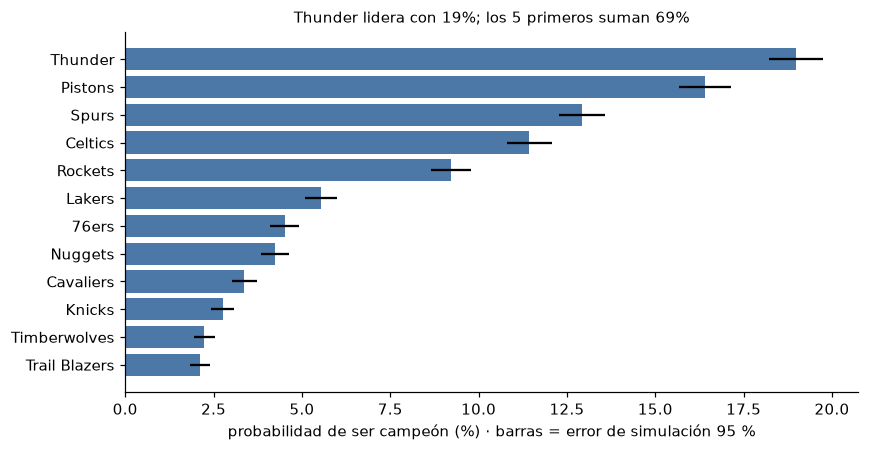

In [7]:
client = NbaClient()
history = load_games(client, season_labels(2015, 2025))
schedule = load_schedule(client, "2026-27", max_age=timedelta(hours=6))
conferences = load_conferences(client, "2026-27")
state = build_season_state(history, schedule, conferences, "2026-27", TUNED_ELO)
print(
    f"{state.games_played} partidos jugados hasta el {state.as_of.date()} (~{state.games_played * 2 / 30:.0f} por equipo)"
)
print(
    f"El calendario lista {state.scheduled_min}-{state.scheduled_max} partidos por equipo; "
    f"{state.owed_total} partidos-equipo se simulan contra un rival promedio"
)

sim = simulate_season(
    state.ratings,
    state.conferences,
    state.current_wins,
    state.remaining,
    state.extra_games,
    SimConfig(n_sims=10_000, seed=0),
).table
sim = sim.join(conferences.set_index("team_id")[["team", "conference"]])
view = sim.sort_values("p_champion", ascending=False)[
    [
        "team",
        "conference",
        "elo",
        "current_wins",
        "exp_wins",
        "wins_p10",
        "wins_p90",
        "p_playoffs",
        "p_finals",
        "p_champion",
    ]
]
print(view.head(10).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4.2))
top = view.head(12).iloc[::-1]
err = 1.96 * np.sqrt(top["p_champion"] * (1 - top["p_champion"]) / 10_000) * 100
ax.barh(top["team"], top["p_champion"] * 100, xerr=err, color="#4C78A8")
ax.set_xlabel("probabilidad de ser campeón (%) · barras = error de simulación 95 %")
ax.set_title(
    f"{view['team'].iloc[0]} lidera con {view['p_champion'].iloc[0]:.0%}; los 5 primeros suman "
    f"{view['p_champion'].head(5).sum():.0%}",
    fontsize=10,
)
plt.tight_layout()
plt.show()

**Cómo leer esto.** Con ~7 partidos por equipo, el rating de cada equipo es casi el del año pasado (regresado hacia la media): el simulador dice "así se ve la temporada si los equipos son como la temporada pasada", con rangos muy anchos (más de 15 victorias de ancho en el 80 % para muchos equipos). No sabe de lesiones, traspasos ni descansos. Y las probabilidades de título de los favoritos (~15-20 %) no son una apuesta: según el backtest, el favorito ganó 25 % de las veces (5 de 20), con mucha incertidumbre.

## 6. Resultado vs. hipótesis

No hubo hipótesis previa. Contra las referencias:

| Pregunta | Resultado | Veredicto |
|---|---|---|
| F. ¿Rango del 80 % calibrado? | Congelado: contiene ~59 %. Con incertidumbre de rating 75: ~83 %; fuera de muestra 78-88 % | Demasiado seguro al principio; corregido |
| G. Probabilidad del favorito al título | ~29 % de media; fue campeón 5 de 20 veces (25 %) | Coherente, con mucho margen de error |
| G. ¿Campeón entre los 3 primeros? | 60 % de los casos | Sí, la mayoría |
| Playoffs vs referencias | Brier del simulador < constante y < "top 8 hoy" en todos los cortes | Sí aporta |
| Título vs uniforme | Log score ~2.2 vs 3.40 | Sí, pero 2025-26 fue muy mal (Knicks: 3-6 %) |

**Qué mejorar (no hecho):** actualizar los ratings durante la simulación; incorporar lesiones y descansos (lo que más falta); desempates reales de la NBA; que la incertidumbre del rating dependa de cuántos partidos se llevan; que el Elo use también playoffs; validar el 75 en más temporadas.

## 7. Tus ejercicios

1. **Predice y mide.** Con `rating_sd=75`, mira en la tabla del grid el pivote de cobertura por corte. Antes de abrirlo, predice si el rango del 80 % queda mejor o peor calibrado al 10 % de la temporada que al 70 %, y por qué. Luego compáralo.
2. **El favorito.** Antes de correr la sección 5 con `rating_sd=0`, escribe qué le pasará a la probabilidad de título del favorito (sube o baja) y por qué un modelo "demasiado seguro" hace eso.